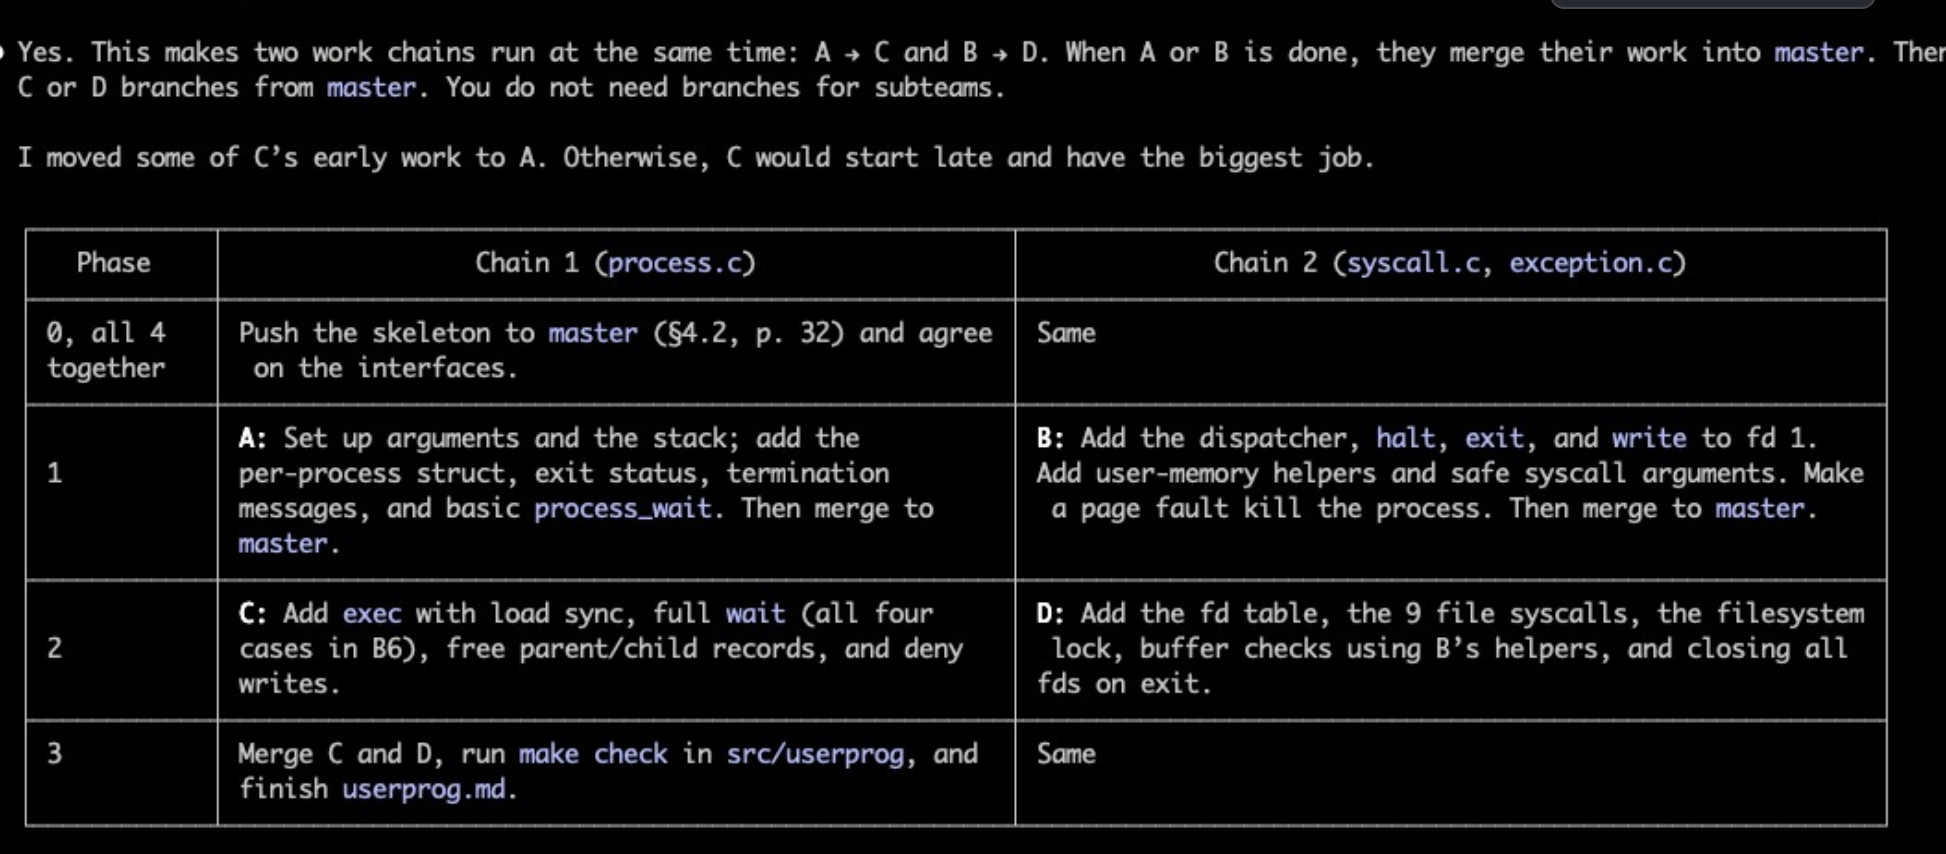

hello. I think I will spend 2 hours working on theory, then 2 hours beginning
implemetnation. I want to now work on understanding the relevant parts that I 
need to understand about PintOS Part II. I think for now, I will only lightly
understand the high level of Part A to D's background theory. But go in depth
for Part D especially, and partiall for part B. 

As you can see, with the repository locally, it already contains Part A and B,
so I will just be working to understand what's going on with those two first,
then after begin implementing. 

I think I will take things in this manner, you can first:

- walk me quickly through Task 2: User Program slides (this is the only "lightly
  understand" that I will do, thank you)
- tell me which relevant pages should I follow through and go through in 
  main_manual, ideally primarily concerning part A (a bit), part B (bit more), 
  and part D (in depth). thank you

```sh
B: Add the dispatcher, HALT, EXIT, and WRITE to fd 1. Add user-memory helpers and safe syscall arguments. Make a page fault kill the process.

D: Add the fd table, the 9 file syscalls, the filessytem lock, buffer checks using B's helpers, and closing all fds on exit. 
```

-- `pagedir` is a pointer to the process's hardware page directory, which
   defines its isolated virtual address space. Every user process gets its own
   page directory so the CPU can translate its virtual addresses into physical
   memory frames. When PintOS switches between processes, it loads this pointer
   into the CPU's `CR3` control register to swap the active memory map.
   If the thread is a pure kernel thread instead of a user process, this pointer
   remains `NULL`






-- A HARDWARE PAGE DIRECTORY is the physical lookup table in RAM that the CPU's
   memory management unit reads to perform this address translation. On 32-bit
   x86 systems, it is an array of 1,024 32-bit entries (`uint32_t`), where each
   entry points to a secondary page table that 


-- An ISOLATED VIRTUAL ADDRESS SPACE is a private illusion of memory that the
   operating system gives to each user program. Every program believes it owns
   the entire memory map from address zero upward, so two processes can use the
   exact same pointer address without colliding. The OS maps each program's 
   fake virtual addresses to separate physical RAM locations behind the scenes.
   If a user program tries to read or write an address outside its own map, the 
   hardwre immediately traps into the kernel and kills the offending process.

-- ... after startup, the process itself controls how much physical memory backs
   its virtual space by calling ssytem calls like `sbrk()` or `mmap()` 
   (triggered by `malloc` or an LLM framework), causing the kernel to allocate
   and wire new physical pages into `pagedir` on demand.


```c
/* Looks up the physical address that corresponds to user virtual
   address UADDR in PD.  Returns the kernel virtual address
   corresponding to that physical address, or a null pointer if
   UADDR is unmapped. */
void *
pagedir_get_page (uint32_t *pd, const void *uaddr) 
{
  uint32_t *pte;

  ASSERT (is_user_vaddr (uaddr));
  
  pte = lookup_page (pd, uaddr, false);
  if (pte != NULL && (*pte & PTE_P) != 0)
    return pte_get_page (*pte) + pg_ofs (uaddr);
  else
    return NULL;
}
```

   `pagedir_get_page()` checks if a user virtual address (`uaddr`) is mapped to
   a Physical RAM in the page directory

   Virtual ranges overlap isntead of partitioning. In physical RAM, the kernel
   gives each process a separate memory slice. In virtual memory, every program gets the exact same address range from `0x08048000` to 
   `0xbfffffff`. Process 1 and Process 2 both use virtual address `0x08048000`,
   which maps to different physical frames. 

   Second, there is no single giant kernel map that takes an integer process ID
   . Instead, each process owns a personal lookup table called `pagedir`. 
   In codebase, this pointer lives at 
   `thread_current ()->process->pagedir` ... 

   each process owns a personal lookup table

   The `uaddr` is

In [ ]:
page directory (4 byte * 1024)
   -> points at *pagedir
   each pagedir[N] points to a single *Page_Table
   each pt[N] == pt[0..1023] points to a 4KB physical frame 

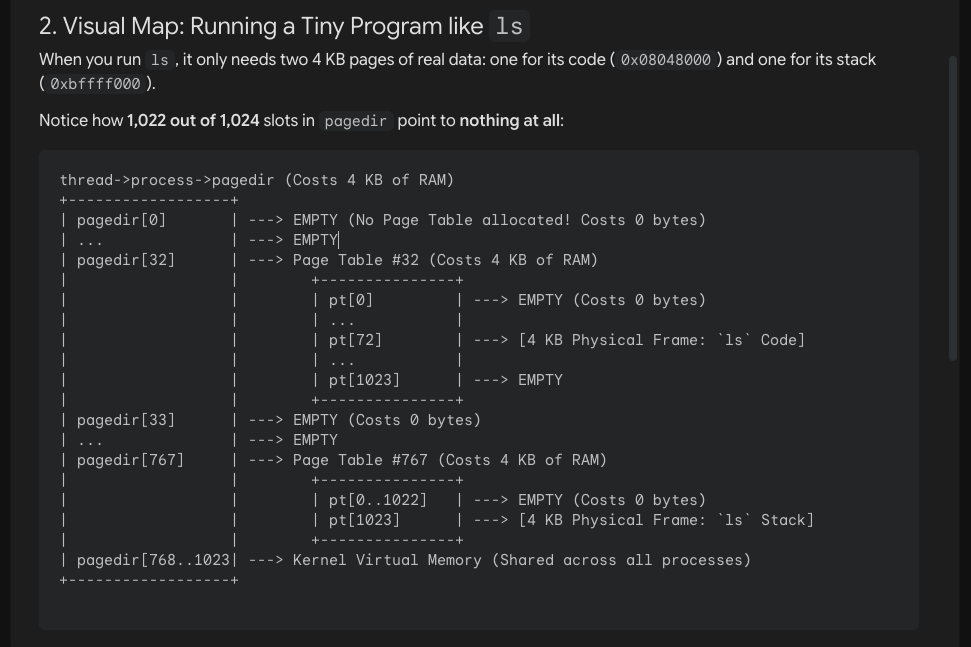

`Page Directory Element -> Page Table Element -> 4 KB page`ah oka

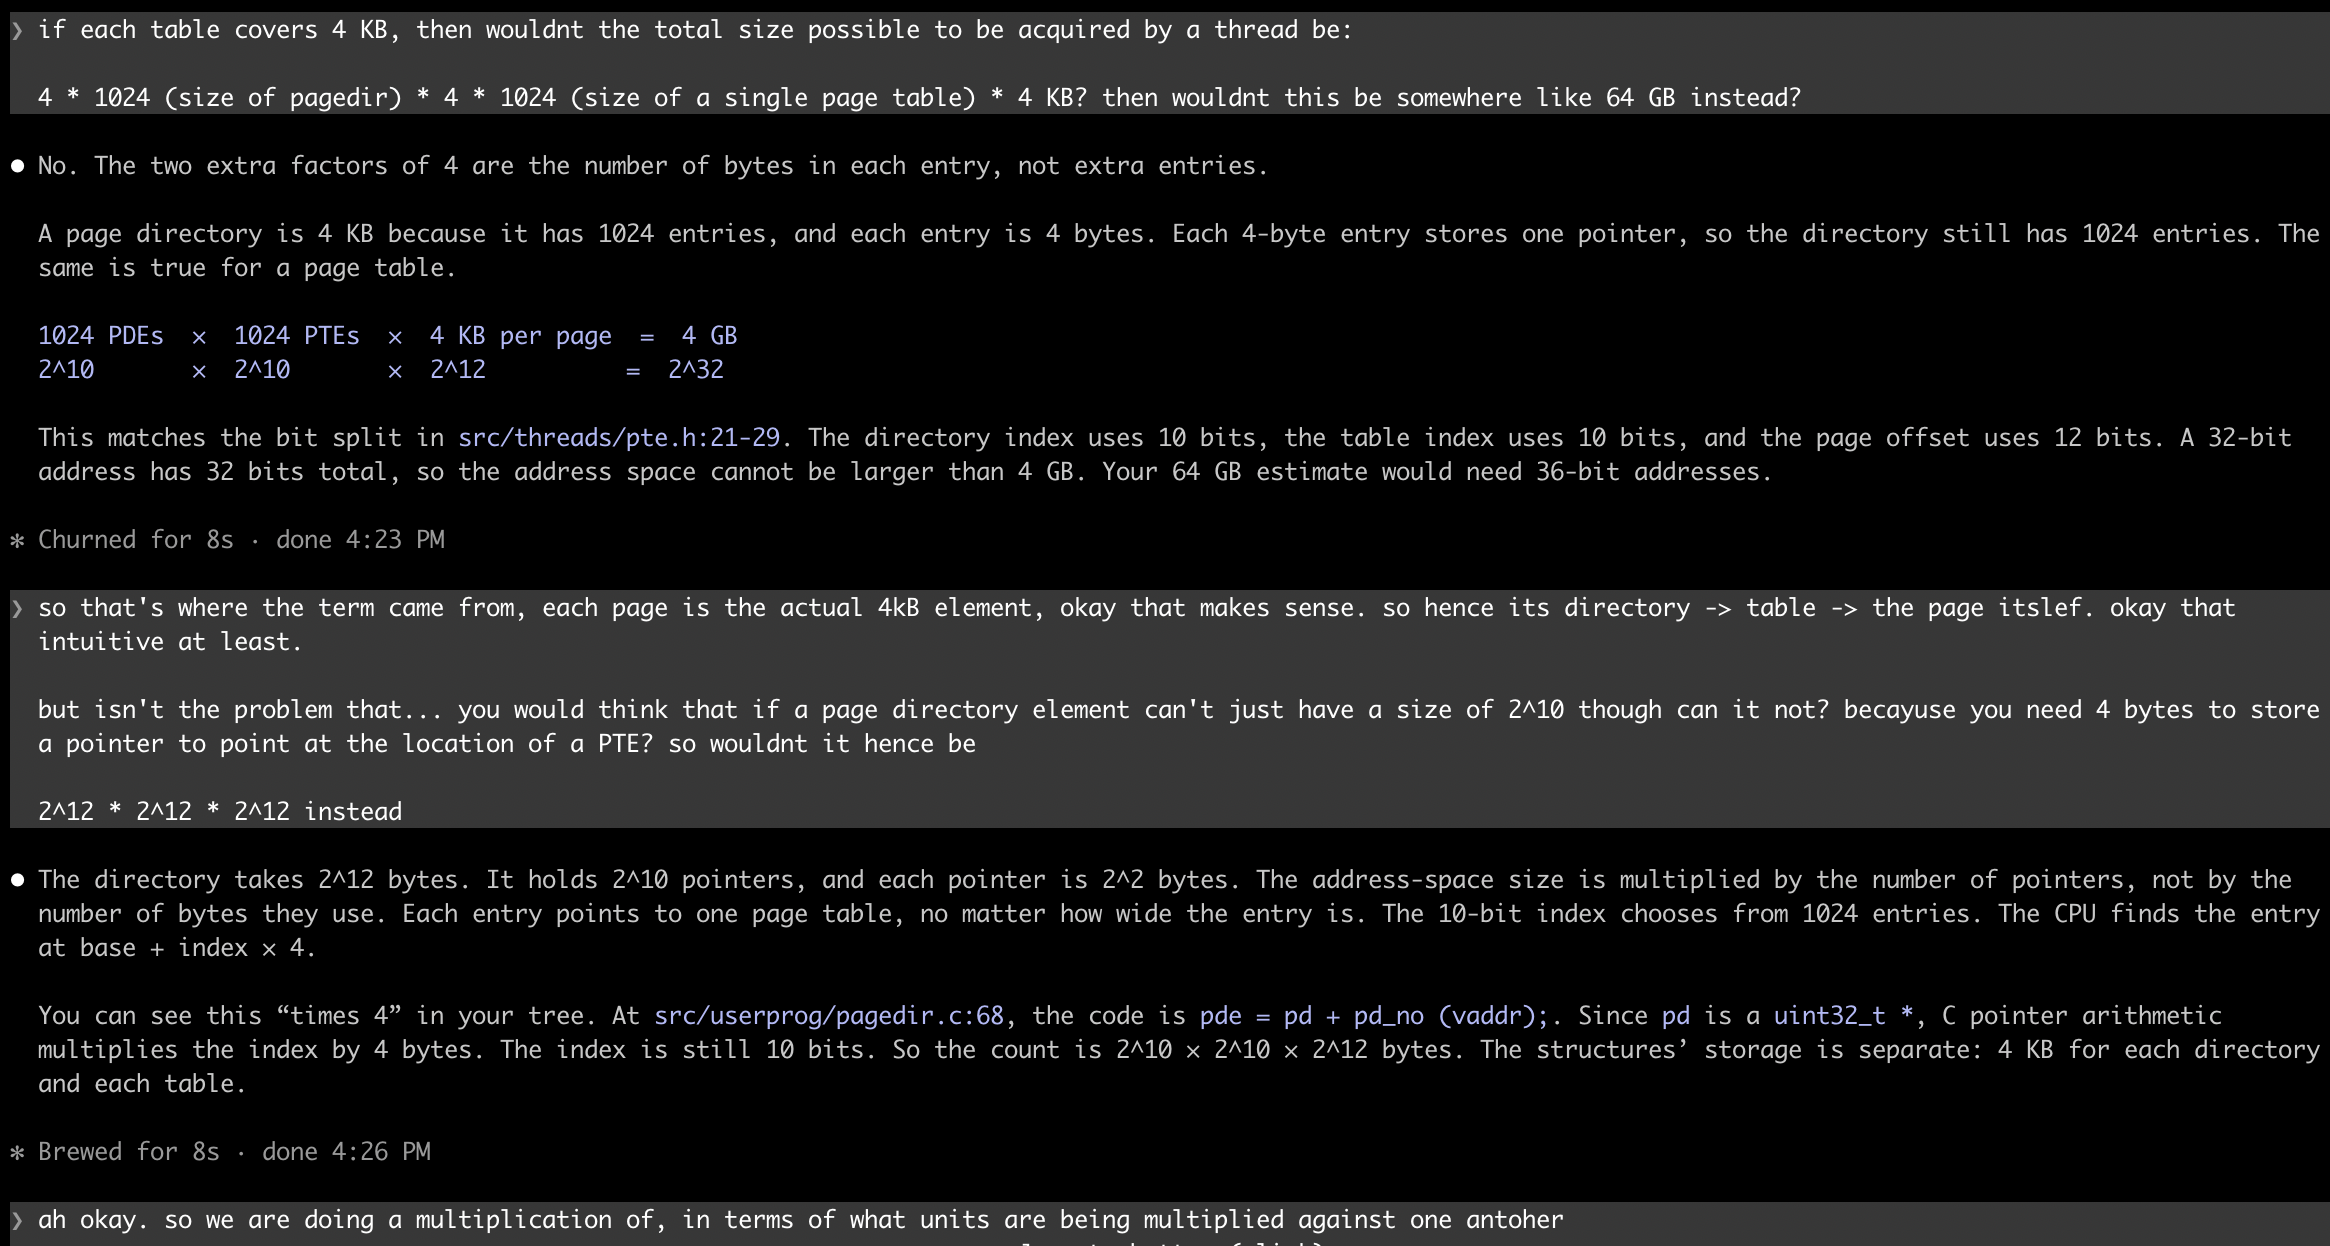

```c
thread -> process                   
        struct thread {
            ...
            struct process *process;    // <-- IMPORTANT
            ...
        }
process -> page directory           
        struct process {
            uint32_t *pagedir;          // Process page directory
            ...
        }
directory created when loading
what `pagedir_create` does
directory loaded into CR3
address split
PDE -> page table -> PTE
PTE -> page
```

   implement four specific mechanisms:
   1. ARGUMENT PASSING (`process.c`): Parsing the command string 
      (`ls -a foo`) and manually pushing `argv` strings, word-aligned pointers,
      and `argc` onto the brand-new user stack before jumping to user mdode.

   2. USER MEMORY VALIDATION (`syscall.c` and `exception.c`): Checking every
      user pointer with `pagedir_get_page()` and semaphores so `exec`, `wait`,
      and `exit` work cleanly even if a child xits before the parent waits, or
      the parent dies first. 
   
   3. PROCESS LIFECYCLE (`process.c`): Coordinating parent and child processes 
      using `struct child_record` and semaphores so `exec`, `wait`, and `exit`
      work cleanly if a child exits before the parent waits, or the parent
      dies first.

   4. SYSTEM CALLS & FILE DESCRIPTORS (`syscall.c`): Implementing the 13 
      syscalls (...), managing the per-process `fd_table`, Synchronisation over
      the global file system, and calling `file_deny_write()` on running executables.



   Mapping the kernel in every process makes it faster to enter the kernel. A
   system call or timer interrupt can run kernel code right away because the 
   kernel is already in the current page directory. Otherwise, each system call
   would reload CR3 and clear the TLB twice... once when entering the kernel
   and once when leaving it ... it also lets the kernel read a user pointer
   directly ... for example, during `write (fd, buf, size)`, the kernel reads
   `buf` at its user address in the same address space. 

VIRTUAL (what one process sees)          PHYSICAL (the RAM sticks)
0xffffffff ┐ unmapped                     0x00400000 ┐ end of RAM (4 MB)
0xc0400000 ┘                                         │ user pool    palloc.c:60
0xc0000000 + x  ───────────── same as ──→ x          │ kernel pool  palloc.c:59
0xc0020000  kernel code _start            0x00100000 ┘ free RAM starts (palloc.c:49)
0xc0000000  PHYS_BASE   vaddr.h:53        0x00020000   kernel image  LOADER_KERN_BASE loader.h:9
─────────── user above / kernel below ─   0x00007c00   loader        LOADER_BASE loader.h:5
0xbfffffff ┐ user stack, 1 page           0x00000000
0xbffff000 ┘ process.c:733, grows down
   ...       ~3 GB unmapped gap
0x08048000   user code start  user.lds:9
0x00000000   NULL, never mapped

   A `page` is a 4 KB block of virtual address
   A `frame` is a 4 KB block of physical RAM
   The page table (PTE) maps each page to a frame


Physical address
Virtual address

## Double Mapping? 
   The double mapping is needed because paging is always on, so even the kernel
   must 

❯ fine, so should i instead say. MMU looksup 0xbffff000, translates to 0x00300000, and throws if page fault exist during this process

  whilst ssycall does its conventional calculation which returns 0x00300000 + 0xc0000000

Yes, that’s correct:

1. The MMU translates virtual address 0xbffff000 to physical address 0x00300000. It raises a page fault if any step fails.
2. In the syscall, pagedir_get_page does the same walk in software. It returns 0x00300000 + 0xc0000000, which is virtual address 0xc0300000.

```c
A. ls reads its stack
ls: read virtual 0xbffff000
    MMU: PDE at physical 0x00105000 + 767×4    → page table at physical 0x00106000
    MMU: PTE at physical 0x00106000 + 1023×4   → frame at physical 0x00300000
    MMU: read physical 0x00300000              → data into an ls register

B. A syscall looks up the same frame
kernel: pagedir_get_page (pd = virtual 0xc0105000, virtual 0xbffff000)
    kernel: read entry 767 at virtual 0xc0105bfc
        MMU: PDE at physical 0x00105000 + 768×4    → kernel table at physical 0x00102000
        MMU: PTE at physical 0x00102000 + 0x105×4  → frame at physical 0x00105000
        MMU: read physical 0x00105bfc              → value: physical 0x00106000
    kernel: add 0xc0000000                         → virtual 0xc0106000   (pte.h:80)
    kernel: read entry 1023 at virtual 0xc0106ffc
        MMU: PDE at physical 0x00105000 + 768×4    → kernel table at physical 0x00102000
        MMU: PTE at physical 0x00102000 + 0x106×4  → frame at physical 0x00106000
        MMU: read physical 0x00106ffc              → value: physical 0x00300000
    kernel: add 0xc0000000                         → return virtual 0xc0300000   (pte.h:103)

C. The kernel reads the data
kernel: read virtual 0xc0300000
    MMU: PDE at physical 0x00105000 + 768×4    → kernel table at physical 0x00102000
    MMU: PTE at physical 0x00102000 + 0x300×4  → frame at physical 0x00300000
    MMU: read physical 0x00300000              → data into a kernel register
```

# Lesson learned today, try and learn things from reading code instead
# of theory spam

Yes, for Pintos on the 32-bit x86 architecture, the hardware MMU strictly and exclusively works on the page directory pointer stored in the %cr3 register

   You will need to interface the file system code for this task, because user
   programs are loaded from the file system and many of the system calls you 
   must implement deal with the file system. However, the focus of this task is
   not the file system, so we have provided a simple but complete rfile system 
   in the `filesys` directory ... look over the interfaces to understand how to 
   use the file system, and especially its many limitations. 

   There is no need to modify the file system code for this task, and so we 
   recommend that you do not. Working on the file system is likely to
   distract you from this task's focus ...

   ... following limitations ... 

   - Coarse-grained synchronisation. To prevent concurrent filesystem accesses
     from interfering with one another, the provided code in `filesys.c` and
     `file.c` is synchronised using a 

```c
/* Internal lock for file system mutual exclusion */
static struct lock filesys_lock;
```
     No finer-grained synchronisation is expected.
   - File size is fixed at creation time. The root directory is represented as a
     file, so the number of files that may be created is also limited


## 4.3.4 System Calls

   Implement the system call handler in `userprog/syscall.c`. The skeleton 
   implementation we provides "handles" system calls by terminating the process.
   It will retrieve the system call number, then any system call arguments, and
   carry out appropriate actions.

   Implement the following system calls. The prototypes listed are those seen 
   by a user program that includes `lib/user/syscall.h` (This header, and all
   others in `lib/user`, are for use by user program only.)




```c
static bool syscall_create (const char *file, unsigned initial_size);
```
   Creates a new file called `FILE` initilaly `INITIAL_SIZE` bytes in size. 
   Returns true if successful, false otherwise. Creating a new file does not 
   open it: opening the new file is a separate operation which require
   a `open` system call.


```c
static bool syscall_remove (const char *file);
```
   Deletes the file called `FILE`. Returns true if succesful, false otherwise.
   A file may be removed regardless of whether close or open...


```c
static int syscall_open (const char *file);
```
   Opens the file called `FILE`. Returns a non-negative integer handle called a
   "file descriptor" (`fd`), or -1 if the file cannot be opened. 

   File descriptors numbered 0 and 1 are reserved for the console: fd `0`
   (`STDIN_FILENO`) is standard input, fd `1` stdout... The `open` system call
   will never return either of these file descriptors, which are valid as
   system call arguments only as explicitly described below. 

   Each process has an independent set of file descriptors... File descriptors
   are not inherited by child processes. 

   When a single file is opened more than once, whether by a single process or
   different processes, each `open` returns a new file descriptor. Different
   file descriptors for a single 




   The system call handler defines 

---

```c
┌──────┬─────────────────────────────────────────┬─────────────────────────────┬───────┬──────────────────────────────────────┐
│ Step │            What you fill in             │            Where            │ Lines │         Test that proves it          │
├──────┼─────────────────────────────────────────┼─────────────────────────────┼───────┼──────────────────────────────────────┤
│ 1    │ open and an fd counter                  │ process.h, process.c,       │ ~30   │ open-normal, open-missing,           │
│      │                                         │ syscall.c                   │       │ open-twice                           │
├──────┼─────────────────────────────────────────┼─────────────────────────────┼───────┼──────────────────────────────────────┤
│ 2    │ close                                   │ syscall.c                   │ ~10   │ close-normal, close-twice,           │
│      │                                         │                             │       │ close-bad-fd                         │
├──────┼─────────────────────────────────────────┼─────────────────────────────┼───────┼──────────────────────────────────────┤
│ 3    │ create and remove                       │ syscall.c                   │ ~15   │ create-normal, create-empty,         │
│      │                                         │                             │       │ create-exists                        │
├──────┼─────────────────────────────────────────┼─────────────────────────────┼───────┼──────────────────────────────────────┤
│ 4    │ read (keyboard and file)                │ syscall.c                   │ ~25   │ read-normal, read-bad-ptr,           │
│      │                                         │                             │       │ read-stdout                          │
├──────┼─────────────────────────────────────────┼─────────────────────────────┼───────┼──────────────────────────────────────┤
│ 5    │ write to files                          │ syscall.c                   │ ~15   │ write-normal, write-bad-fd           │
├──────┼─────────────────────────────────────────┼─────────────────────────────┼───────┼──────────────────────────────────────┤
│ 6    │ filesize, seek, tell, and close all fds │ syscall.c, process.c        │ ~35   │ multi-child-fd, then full make check │
│      │  on exit                                │                             │       │                                      │
└──────┴─────────────────────────────────────────┴─────────────────────────────┴───────┴──────────────────────────────────────┘
```